saved the figure


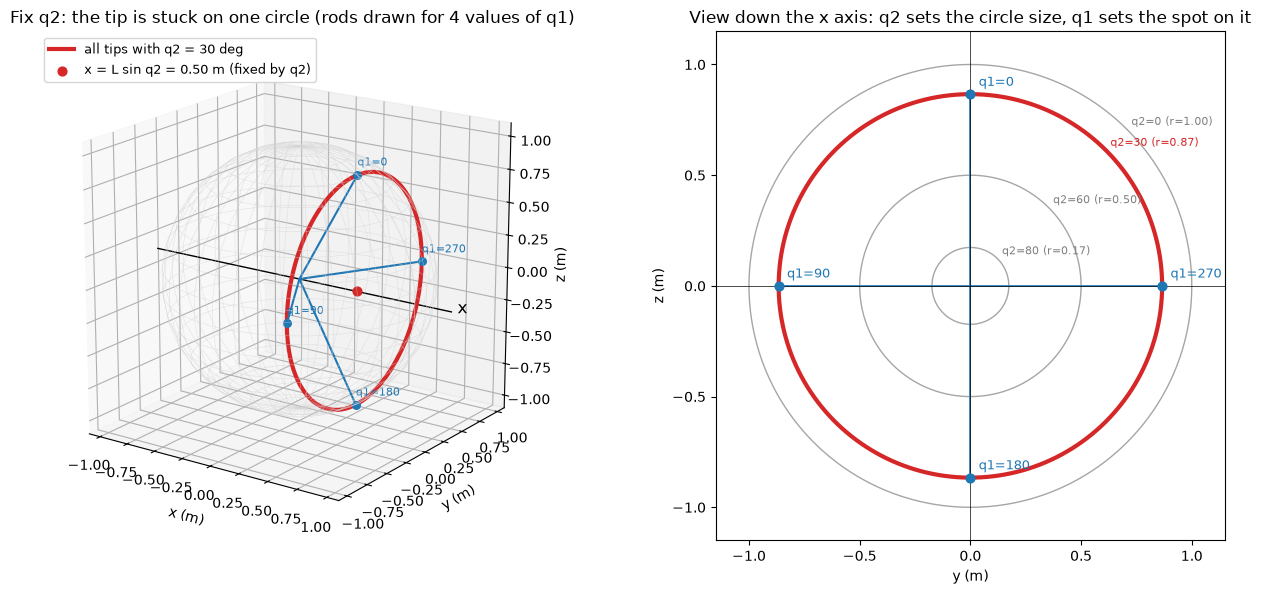

In [1]:
import os
from datetime import datetime
import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# =====================================================================
# STEP 1: tip formula
# What we have: rod length L (m), hinge angles q1 (about x) and q2 (about y), in rad
# What we want: the tip position (x, y, z) in m for any pose
# Why: every picture below is this one formula evaluated at chosen angles
#   tip = L * ( sin q2, -sin q1 cos q2, cos q1 cos q2 )
# =====================================================================
L = 1.0
Q2_HIGHLIGHT = np.deg2rad(30.0)


def tip(q1, q2):
    return L * np.array([np.sin(q2) * np.ones_like(q1),
                         -np.sin(q1) * np.cos(q2),
                         np.cos(q1) * np.cos(q2)])


# =====================================================================
# STEP 2: what q2 fixes
# What we have: one chosen q2
# What we want: the set of all tips reachable by sweeping q1 over a full turn
# Why: x = L sin q2 does not depend on q1, so the tips form a circle
#   of radius L cos q2 in the plane x = L sin q2
# =====================================================================
q1_sweep = np.linspace(0, 2 * np.pi, 400)
circle = tip(q1_sweep, Q2_HIGHLIGHT)
x_fixed = L * np.sin(Q2_HIGHLIGHT)
radius = L * np.cos(Q2_HIGHLIGHT)

# =====================================================================
# STEP 3: figure
# What we have: the circle for q2 = 30 deg and the ball of all reachable tips
# What we want: left, a 3D view; right, the view down the x axis
# Why: the right panel shows q2 setting the circle size and q1 the spot on it
# =====================================================================
fig = plt.figure(figsize=(13, 6))

ax = fig.add_subplot(1, 2, 1, projection="3d")
u, v = np.meshgrid(np.linspace(0, 2 * np.pi, 36), np.linspace(0, np.pi, 18))
ax.plot_wireframe(L * np.cos(u) * np.sin(v), L * np.sin(u) * np.sin(v), L * np.cos(v),
                  color="lightgray", linewidth=0.4, alpha=0.6)
ax.plot([-1.3, 1.3], [0, 0], [0, 0], color="black", linewidth=1)
ax.text(1.35, 0, 0, "x", fontsize=12)
ax.plot(*circle, color="tab:red", linewidth=3, label="all tips with q2 = 30 deg")
ax.scatter([x_fixed], [0], [0], color="tab:red", s=40, label=f"x = L sin q2 = {x_fixed:.2f} m (fixed by q2)")
for deg in (0, 90, 180, 270):
    p = tip(np.array(np.deg2rad(deg)), Q2_HIGHLIGHT)
    ax.plot([0, p[0]], [0, p[1]], [0, p[2]], color="tab:blue", linewidth=1.5)
    ax.scatter(*p, color="tab:blue", s=30)
    ax.text(p[0], p[1], p[2] + 0.07, f"q1={deg}", fontsize=8, color="tab:blue")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_zlabel("z (m)")
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_zlim(-1.1, 1.1)
ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=18, azim=-55)
ax.set_title("Fix q2: the tip is stuck on one circle (rods drawn for 4 values of q1)")
ax.legend(loc="upper left", fontsize=9)

ax2 = fig.add_subplot(1, 2, 2)
t = np.linspace(0, 2 * np.pi, 400)
for deg in (0, 30, 60, 80):
    r = L * np.cos(np.deg2rad(deg))
    is_main = deg == 30
    ax2.plot(r * np.sin(t), r * np.cos(t),
             color="tab:red" if is_main else "gray",
             linewidth=3 if is_main else 1, alpha=1 if is_main else 0.7)
    ax2.text(r * np.sin(np.pi / 4) + 0.02, r * np.cos(np.pi / 4) + 0.02, f"q2={deg} (r={r:.2f})",
             fontsize=8, color="tab:red" if is_main else "gray")
for deg in (0, 90, 180, 270):
    p = tip(np.array(np.deg2rad(deg)), Q2_HIGHLIGHT)
    ax2.plot([0, p[1]], [0, p[2]], color="tab:blue", linewidth=1.2)
    ax2.scatter(p[1], p[2], color="tab:blue", s=40, zorder=5)
    ax2.annotate(f"q1={deg}", (p[1], p[2]), textcoords="offset points", xytext=(6, 6),
                 fontsize=9, color="tab:blue")
ax2.set_aspect("equal")
ax2.set_xlim(-1.15, 1.15)
ax2.set_ylim(-1.15, 1.15)
ax2.set_xlabel("y (m)")
ax2.set_ylabel("z (m)")
ax2.axhline(0, color="black", linewidth=0.5)
ax2.axvline(0, color="black", linewidth=0.5)
ax2.set_title("View down the x axis: q2 sets the circle size, q1 sets the spot on it")

fig.tight_layout()
path = os.path.join(RESULT_DIR, f"q2_fixes_circle_{TIMESTAMP}.png")
fig.savefig(path, dpi=150)
print("saved the figure")
plt.show()